[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/numpy-arrays.ipynb)

# NumPy: Arrays and Indexing

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Read an array's shape, dtype and memory and explain why arrays beat loops.</li>
<li>Tell views from copies and avoid the aliasing bug.</li>
<li>Use boolean masks and NaN-aware functions to find and handle bad data.</li>
<li>Turn raw records into a grid with bincount and reshape, and read axis correctly.</li>
</ul>
</div>

**Prerequisites:** Python basics. **Dataset:** NYC Taxi (January 2023). **Time:** about 35 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_taxi, style

style.apply()
pd.set_option("display.width", 120)

## The situation

Almost everything in the Python data stack (pandas, scikit-learn, PyTorch) is built on one idea: **a block of numbers of a single type, stored contiguously, that you operate on all at once**. That is the NumPy array. Learn it well and the rest of the ecosystem stops being mysterious.

We use a real table: every yellow-cab trip in New York City in January 2023, about three million rows. That is big enough for the performance points to be real, and messy enough that the indexing and masking techniques are needed, not decorative.

In [2]:
taxi = load_taxi("2023-01")
distance = taxi["trip_distance"].to_numpy(copy=True)        # a pandas column -> an independent, writable NumPy array
fare = taxi["fare_amount"].to_numpy(copy=True)
print(type(distance), distance.dtype, distance.shape)
distance[:5]

<class 'numpy.ndarray'> float64 (3066766,)


array([0.97, 1.1 , 2.51, 1.9 , 1.43])

<div class="admonition note">
<p class="admonition-title">pandas 3 note</p>
<p>In pandas 3 (copy-on-write), <code>.to_numpy()</code> without <code>copy=True</code> returns a <em>read-only</em> view, so assigning into it raises an error. That protects your DataFrame from accidental edits. Ask for <code>copy=True</code> when you want an array you can change.</p>
</div>

## 1. What an array is

Four attributes describe any array. Check them whenever something behaves oddly: most NumPy surprises are a wrong `shape` or `dtype`.

In [3]:
pd.Series({
    "shape": distance.shape,
    "ndim (number of axes)": distance.ndim,
    "dtype": distance.dtype,
    "itemsize (bytes per value)": distance.itemsize,
    "total size (MB)": round(distance.nbytes / 1e6, 1),
    "as float32 (MB)": round(distance.astype(np.float32).nbytes / 1e6, 1),
}, name="distance").to_frame()

,distance
shape,"(3066766,)"
ndim (number of axes),1
dtype,float64
itemsize (bytes per value),8
total size (MB),24.5
as float32 (MB),12.3


Every value takes 8 bytes (`float64`). Switching to `float32` halves the memory at the cost of precision, a common choice for deep-learning data. (A Python list of the same numbers would be several times larger, since each element is a full Python object.)

<div class="admonition math">
<p class="admonition-title">Maths ↔ code</p>
<p>The mean is <code>distance.mean()</code>; the standard deviation is <code>distance.std()</code>. NumPy's <code>std</code> divides by <em>n</em> (<code>ddof=0</code>); pandas divides by <em>n</em> − 1 (the sample estimate). That is the classic reason the two disagree: pass <code>ddof=1</code> to NumPy to match pandas.</p>
</div>

## 2. Why arrays: whole-array operations

Suppose we want the fare per mile for every trip that went somewhere. Compare a Python loop with the equivalent array expression on 300,000 trips.

In [4]:
n = 300_000
d, f = distance[:n], fare[:n]

t0 = time.perf_counter()
total = 0.0
for i in range(n):                                    # one Python-level step per element
    if d[i] > 0:
        total += f[i] / d[i]
loop_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
moved = d > 0
vector_total = (f[moved] / d[moved]).sum()            # the same thing, in compiled code over the whole array
vector_seconds = time.perf_counter() - t0

assert np.isclose(total, vector_total)               # identical answer
print(f"loop: {loop_seconds:.3f} s   vectorised: {vector_seconds:.5f} s   -> about {loop_seconds / vector_seconds:.0f}x faster")
assert loop_seconds / vector_seconds > 10

loop: 0.100 s   vectorised: 0.00598 s   -> about 17x faster


The answer is identical and the array version is dramatically faster, because the loop makes 300,000 trips through the Python interpreter while the array expression makes one trip into compiled code. **Rule of thumb: if you are writing a `for` loop over array elements, look for a whole-array way to say it.** The exact ratio depends on your machine, but it will be large.

## 3. Indexing, slicing, and the view trap

Slices of an array are **views**: they share memory with the original instead of copying it. That is fast, and it is also the source of a classic bug.

In [5]:
first_ten = distance[:10]                              # a slice
print("shares memory with the original:", np.shares_memory(first_ten, distance))

backup = distance[:3].copy()
first_ten[0] = 999.0                                   # change the slice ...
print("original after editing the slice:", distance[0], "(was", backup[0], ")")
first_ten[0] = backup[0]                               # restore it

picked = distance[[0, 2, 4]]                           # fancy indexing (a list of positions) makes a COPY
print("fancy indexing shares memory:", np.shares_memory(picked, distance))

shares memory with the original: True
original after editing the slice: 999.0 (was 0.97 )
fancy indexing shares memory: False


**The rule:** basic slices (`a[2:9]`, `a[::2]`) give views; indexing with a list of positions or a boolean mask gives a copy. When you need an independent array, call `.copy()` explicitly.

## 4. Boolean masks: selecting by condition

Real data has junk in it, and masks are how you find it. A mask is an array of `True`/`False`, one per element. Combine masks with `&`, `|` and `~` (not `and`/`or`), and **put each comparison in parentheses**, because `&` binds more tightly than `>`.

In [6]:
negative_fare = fare < 0
zero_distance = distance == 0
absurd_distance = distance > 100                      # no taxi ride in New York is over 100 miles
suspect = negative_fare | zero_distance | absurd_distance

print(f"negative fares:     {negative_fare.sum():>9,}")
print(f"zero distance:      {zero_distance.sum():>9,}")
print(f"over 100 miles:     {absurd_distance.sum():>9,}   (the longest 'trip' is {distance.max():,.0f} miles)")
print(f"any of the above:   {suspect.sum():>9,}  ({suspect.mean():.1%} of all trips)")

good = ~suspect
print(f"\nmean distance, all trips: {distance.mean():.2f} miles;  after removing the suspect ones: {distance[good].mean():.2f} miles")

negative fares:        25,049
zero distance:         45,862
over 100 miles:            88   (the longest 'trip' is 258,928 miles)
any of the above:      67,985  (2.2% of all trips)

mean distance, all trips: 3.85 miles;  after removing the suspect ones: 3.42 miles


Removing just 2.2% of dubious rows shifts the average noticeably, and the *longest trip is a quarter of a million miles*, roughly the distance to the Moon. This is why you look at the extremes before trusting any average. (`.sum()` of a mask counts the `True` values, and `.mean()` gives their share.)

`np.where(condition, if_true, if_false)` builds a new array element by element, which is how you recode values without a loop:

In [7]:
fare_class = np.where(fare < 0, "refund or error", np.where(fare < 10, "short", "long"))
pd.Series(fare_class).value_counts()

long               2122403
short               919314
refund or error      25049
Name: count, dtype: int64

## 5. Missing values: `NaN` is not equal to anything

Float arrays mark missing data with `NaN` ("not a number"). It poisons arithmetic and fails every comparison, including with itself.

In [8]:
passengers = taxi["passenger_count"].to_numpy()
print("missing passenger counts:", np.isnan(passengers).sum())
print("NaN == NaN ?", np.nan == np.nan)
print("plain mean:", passengers.mean(), "   nan-aware mean:", round(np.nanmean(passengers), 3))

missing passenger counts: 71743
NaN == NaN ? False
plain mean: nan    nan-aware mean: 1.363


One `NaN` makes the plain mean `nan`. Use the `np.nan*` family (`nanmean`, `nansum`, `nanstd`, ...) or filter with `~np.isnan(a)`. Never test for missing values with `== np.nan`; use `np.isnan`.

## 6. Reshaping and the meaning of `axis`

The most useful trick for tabular counting is to compute a single flat index and **reshape** the counts into a grid. Here: how many trips start in each (weekday, hour) combination? `np.bincount` counts occurrences of each integer, and 7 × 24 = 168 cells reshape into a week.

shape: (7, 24) | total trips: 3066718


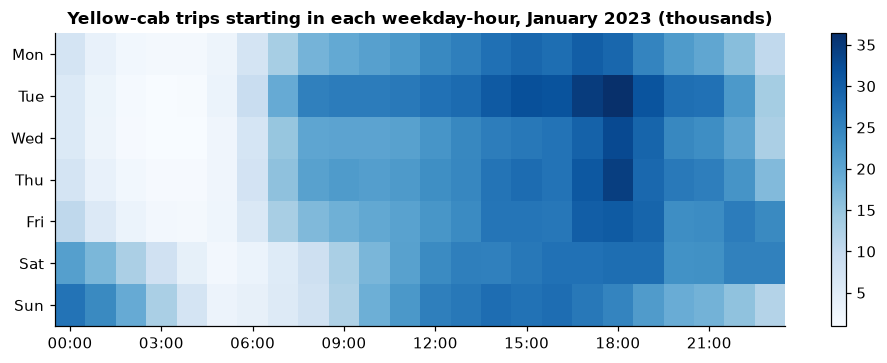

busiest slot: Tue at 18:00 with 36,405 trips


In [9]:
pickup = taxi["tpep_pickup_datetime"]
in_january = (pickup.dt.to_period("M") == "2023-01").to_numpy()          # drop the few mis-dated trips
weekday, hour = pickup.dt.dayofweek.to_numpy()[in_january], pickup.dt.hour.to_numpy()[in_january]

counts = np.bincount(weekday * 24 + hour, minlength=7 * 24).reshape(7, 24)   # rows = weekday, columns = hour
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("shape:", counts.shape, "| total trips:", counts.sum())

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(counts / 1000, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), days); ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)]); ax.grid(False)
ax.set(title="Yellow-cab trips starting in each weekday-hour, January 2023 (thousands)"); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

peak_row, peak_col = np.unravel_index(counts.argmax(), counts.shape)
print(f"busiest slot: {days[peak_row]} at {peak_col:02d}:00 with {counts.max():,} trips")

`axis` tells an operation *which dimension to collapse*. On this (7, 24) grid, `counts.sum(axis=0)` collapses the weekdays and leaves 24 hourly totals; `counts.sum(axis=1)` collapses the hours and leaves 7 daily totals. A handy memory: **the axis you name disappears**.

The picture is a city's rhythm: a morning ramp, an evening peak, and a different shape at weekends. `argmax` returns a position in the *flattened* array, and `np.unravel_index` turns it back into (row, column).

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| Editing a slice changes the original | slices are views | `.copy()` |
| `a > 1 & a < 5` raises an error | `&` binds tighter than `>` | `(a > 1) & (a < 5)` |
| Mean is `nan` | a single `NaN` | `np.nanmean` or filter with `np.isnan` |
| `astype(int)` of `1.9` gives `1` | casting truncates, it does not round | `np.round(a).astype(int)` |
| Two means disagree between pandas and NumPy | `ddof` differs (n − 1 vs n) | `ddof=1` |

## Check yourself

<details class="question">
<summary>1. Why is the vectorised version so much faster, when both do the same arithmetic?</summary>

The loop executes Python bytecode once per element, with all the overhead of looking up types and objects each time. The array expression hands the whole block of same-typed numbers to compiled code, which loops in C (often using vector instructions). Same arithmetic, vastly less overhead per element.

</details>

<details class="question">
<summary>2. You take <code>x = a[:5]</code> and set <code>x[0] = 0</code>. Does <code>a</code> change? What if you had used <code>a[[0, 1, 2]]</code>?</summary>

With a basic slice, yes: `x` is a view of `a`, so `a[0]` becomes 0. With a list of positions (fancy indexing) you get a copy, so editing it leaves `a` alone. When in doubt, check `np.shares_memory`, or call `.copy()`.

</details>

<details class="question">
<summary>3. What does <code>np.array([1.9, -1.9]).astype(int)</code> return?</summary>

`array([ 1, -1])`: casting to integer **truncates toward zero**; it does not round. Use `np.round(a).astype(int)` if you want rounding.

</details>

## Exercises

<details class="question">
<summary>What share of trips have a fare above $50? Then: which weekday-hour slot has the <em>fewest</em> trips? Predict both first.</summary>

```python
print(f"{(fare > 50).mean():.2%} of trips have a fare above $50")

quiet_row, quiet_col = np.unravel_index(counts.argmin(), counts.shape)
print(f"quietest slot: {days[quiet_row]} at {quiet_col:02d}:00 with {counts.min():,} trips")
```

About 6.6% of trips cost more than $50, and the first is a one-liner because the mean of a boolean mask is the share of `True`. The second uses `argmin` instead of `argmax`: the quietest slot is **Wednesday at 03:00 with 973 trips**, against 36,405 at the Tuesday 18:00 peak, a ratio of nearly forty to one.

</details>

<details class="question">
<summary>Standardise the distances: subtract the mean and divide by the standard deviation, but compute the mean and standard deviation only from the <em>good</em> trips. What happens to the absurd 258,928-mile trip?</summary>

```python
mu, sigma = distance[good].mean(), distance[good].std()
z = (distance - mu) / sigma
print("z-score of the longest trip:", round(z.max()))
```

It becomes a z-score of roughly 59,000, many orders of magnitude beyond anything plausible. Standardising with statistics from the *cleaned* data makes such rows stand out instead of hiding them, which is a useful trick for spotting data errors.

</details>

## Recap

- An array is a typed block of numbers; check `shape` and `dtype` first when something is off.
- **Whole-array expressions** replace loops and are far faster.
- Slices are **views**; fancy and boolean indexing give **copies**.
- Boolean masks select by condition; combine with `& | ~` and parenthesise comparisons.
- `NaN` is never equal to anything; use `np.isnan` and the `np.nan*` functions.
- `bincount` + `reshape` turns raw records into a grid; the **named axis disappears** when you aggregate.

**Next:** *Vectorisation, broadcasting and linear algebra*.